# Hello World

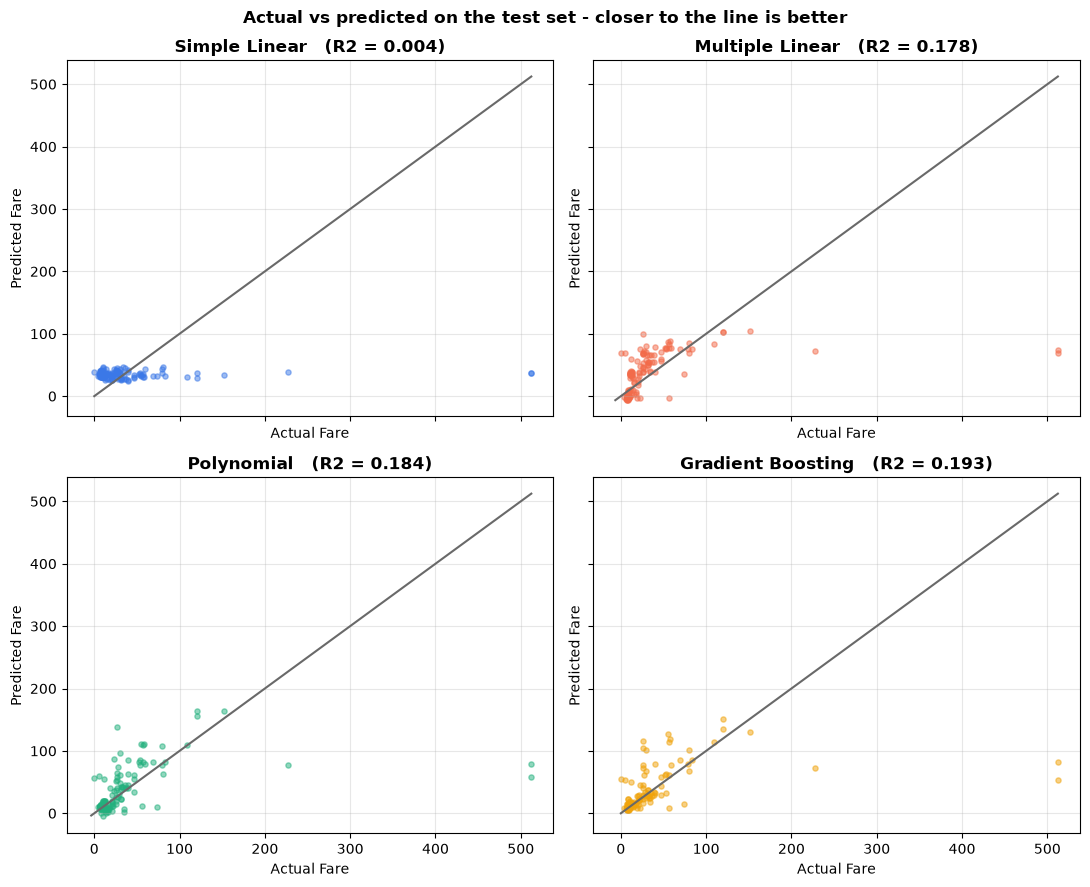

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# 1. load + clean + split (80% train / 20% test)
df = pd.read_csv("titanic.csv")
df["Sex"] = (df["Sex"] == "male") * 1
df = df[["Age", "Pclass", "SibSp", "Parch", "Sex", "Fare"]].dropna()
df = df.sample(frac=1, random_state=42)
X = df[["Age", "Pclass", "SibSp", "Parch", "Sex"]].values
y = df["Fare"].values
n = int(len(df) * 0.8)
X_train, X_test, y_train, y_test = X[:n], X[n:], y[:n], y[n:]

# 2. linear regression: w = (X^T X)^-1 X^T y
def linear(X_train, y_train, X_test):
    X_train = np.column_stack([np.ones(len(X_train)), X_train])
    X_test = np.column_stack([np.ones(len(X_test)), X_test])
    w = np.linalg.pinv(X_train.T @ X_train) @ X_train.T @ y_train
    return X_test @ w

# 3. gradient boosting: keep adding a small "split into 2 groups" fix
def boost(X_train, y_train, X_test):
    pred_train = np.full(len(y_train), y_train.mean())
    pred_test = np.full(len(X_test), y_train.mean())
    for _ in range(50):
        error = y_train - pred_train
        best = 1e18
        for j in range(X_train.shape[1]):
            for t in np.unique(X_train[:, j])[:-1]:
                left = X_train[:, j] <= t
                a, b = error[left].mean(), error[~left].mean()
                loss = ((error[left] - a) ** 2).sum() + ((error[~left] - b) ** 2).sum()
                if loss < best:
                    best, bj, bt, ba, bb = loss, j, t, a, b
        pred_train[X_train[:, bj] <= bt] += 0.1 * ba
        pred_train[X_train[:, bj] > bt] += 0.1 * bb
        pred_test[X_test[:, bj] <= bt] += 0.1 * ba
        pred_test[X_test[:, bj] > bt] += 0.1 * bb
    return pred_test

# 4. plot
def show(pos, name, y_pred):
    r2 = 1 - ((y_test - y_pred) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum()
    plt.subplot(2, 2, pos)
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([0, y_test.max()], [0, y_test.max()], "gray")
    plt.title(f"{name} (R2 = {r2:.3f})")
    plt.xlabel("Actual"); plt.ylabel("Predicted")

show(1, "Simple Linear", linear(X_train[:, :1], y_train, X_test[:, :1]))
show(2, "Multiple Linear", linear(X_train, y_train, X_test))
show(3, "Polynomial", linear(np.column_stack([X_train, X_train**2]), y_train, np.column_stack([X_test, X_test**2])))
show(4, "Gradient Boosting", boost(X_train, y_train, X_test))
plt.tight_layout()
plt.show()